In [49]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [50]:
import pandas as pd

import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
import os

In [75]:
from plotting_ts_tools import (
    calculate_anomaly,
    calculate_anomaly_timeslice,
    line_plot,
    line_plot_min_max,
    select_index,
    cleanup,
    adjust_names,
    adjust_length,
    line_plot_anomaly,
    box_plot_anomaly,
    lineplot_and_boxplot,
    load_era5_csv,
    load_rcms_csv
)

In [52]:
# Select Variables
#
# 50 mm sind sehr wenige
# TR, Regcm hat zu viele sieht komisch aus
#climate_index='R20mm' 
#climate_index= 'DD'
climate_index= 'TG'
#cliamte_index='SU35'
#climate_index='SU40'
#climate_index='TR26'
#climate_index='RRm'

var_meta = select_index(climate_index)
print(var_meta)
# select country and time step
#
#country='Togo'
country='Burkina Faso'
#country='Ivory Coast'
timestep='year'


{'longname': 'mean temperature [°C]', 'longnameK': 'mean temperature [K]', 'unit_base': '°C', 'unit_alt': 'K', 'description': 'Near-surface air temperature'}


In [53]:
# Load the CSV file containing the data for the selected index, country, and time step:
#
path='/work/ch0636/g300047/cicles/climate_fact_data/spavg_afr22/'+climate_index
file_name='climdexCORDEX_AFR22_'+climate_index+'_'+timestep+'_weighted_means.csv'
file_path = os.path.join(path,file_name)
data = pd.read_csv(file_path)

In [54]:
# Load csv file for ERA5
path='/work/ch0636/g300047/cicles/climate_fact_data/spavg_era5/'+climate_index
file_name='climdexERA5_'+climate_index+'_'+timestep+'_weighted_means.csv'
era5_path = os.path.join(path,file_name)
era5data = pd.read_csv(era5_path)

In [55]:
# define output path and filename
#
outputpath='/work/ch0636/g300047/cicles/factsheet_africa/PLOTS/AFR22_timeseries_v2/'+climate_index
#outfile = os.path.join(outputpath,climate_index+'_'+timestep+'_line_plot_sce_color_min_max.png')

if not os.path.exists(outputpath):
    os.makedirs(outputpath)

In [56]:
# The data needs to be cut to the same length for all scenarios and the same time period for all indices.
# cut_data=load_rcms_csv(file_path, country, index, longname, start_date='1971-01-01', end_date='2098-12-31', longnameK=None)
# For TG, we need to load the data with longnameK to convert from K to °C in the load function. 
# For the other indices, we can load the data without longnameK.
#
if climate_index == 'TG':
    cut_data=load_rcms_csv(file_path, country, climate_index, var_meta['longname'], start_date='1971-01-01', end_date='2098-12-31', longnameK=longnameK)
else:
    cut_data=load_rcms_csv(file_path, country, climate_index, var_meta['longname'], start_date='1971-01-01', end_date='2098-12-31', longnameK=None)

In [57]:
# prepare era5 data
era5_cut=load_era5_csv(era5_path, country, climate_index, var_meta['longname'], start_date='1971-01-01', longnameK=longnameK)

Plotting column:  mean temperature [°C]
year mean temperature [°C]
year mean temperature [°C]
Saved plot to:  /work/ch0636/g300047/cicles/factsheet_africa/PLOTS/AFR22_timeseries_v2/TG/line_plot_min_max_TG_year_Burkina_Faso.png


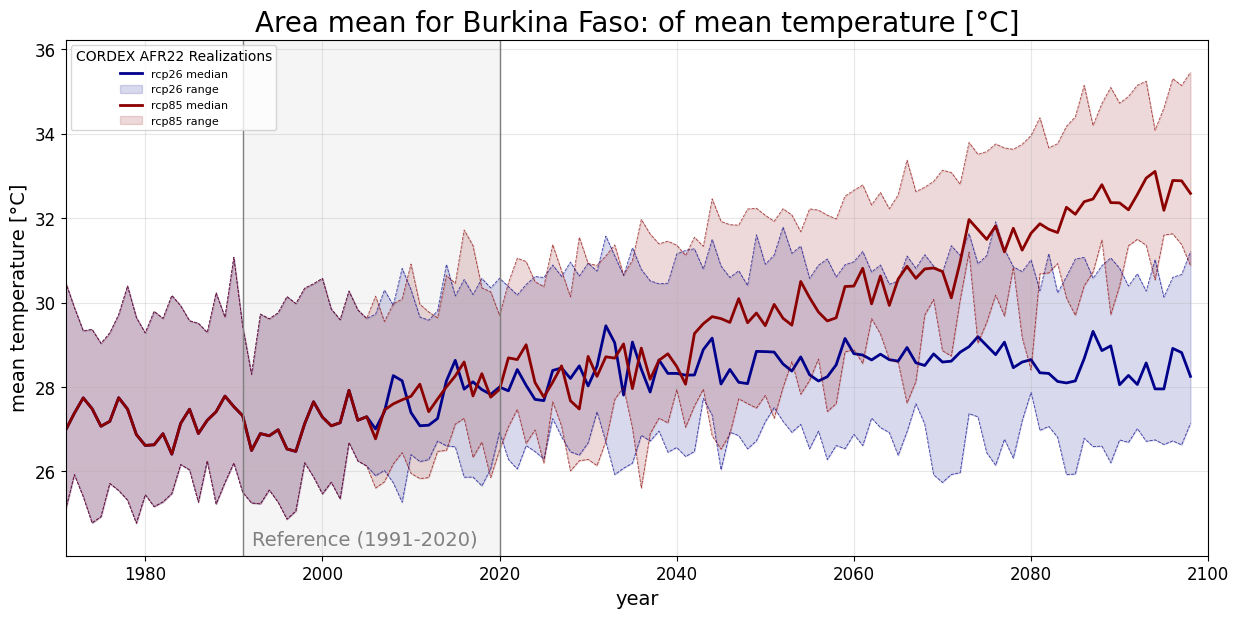

Plotting column:  mean temperature [°C]
year mean temperature [°C]
year mean temperature [°C]
Saved plot to:  /work/ch0636/g300047/cicles/factsheet_africa/PLOTS/AFR22_timeseries_v2/TG/line_plot_min_max_TG_year_Burkina_Faso_ERA5.png


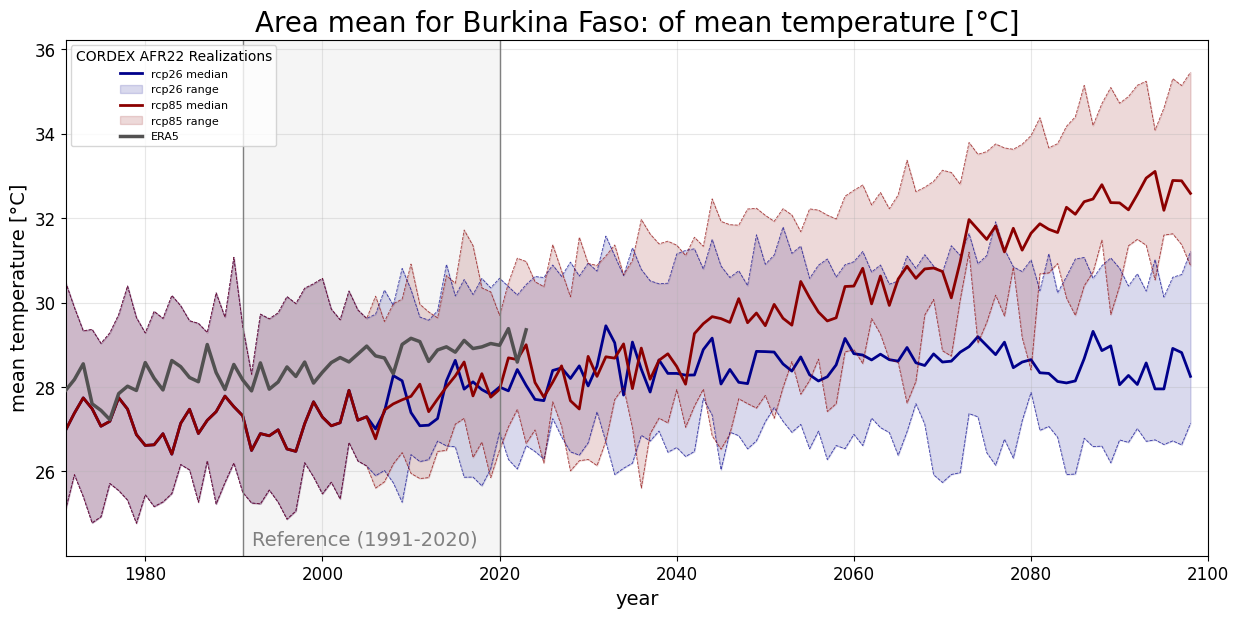

In [58]:
# You can chose if you like to add ERA5 or not
line_plot_min_max(cut_data,'year',longname,climate_index,outputpath,country)#, ylim=(23,37))
line_plot_min_max(cut_data,'year',longname,climate_index,outputpath,country, dfera5=era5_cut)#, ylim=(23,37))

In [71]:
# calculate anomalies
# Returns dataframe with columns: anomaly, running_mean_10yr, running_mean_30yr
df_anomaly_year = calculate_anomaly(cut_data, '1991-01-01', '2020-12-31', var_meta['longname'])
#df.head()

In [60]:
# Mean anomaly per time slice, for each realization and scenario
# Use pre-defined `slices` if available; otherwise fall back to standard ranges
slices_to_use = [
        ("2031-2060", 2031, 2060),
        ("2069-2098", 2069, 2098),
    ]
anom_slice_means = calculate_anomaly_timeslice(df_anomaly_year, slices_to_use)
anom_slice_means.head()

,slice,region,standard_name,realization,scenario,anomaly_mean,years
0,2031-2060,Burkina Faso,air_temperature,AFR-22_GERICS_CLMcom-KIT-CCLM5-0-15_MOHC-HadGE...,rcp26,1.266391,30
1,2031-2060,Burkina Faso,air_temperature,AFR-22_GERICS_CLMcom-KIT-CCLM5-0-15_MOHC-HadGE...,rcp85,2.133046,30
2,2031-2060,Burkina Faso,air_temperature,AFR-22_GERICS_CLMcom-KIT-CCLM5-0-15_MPI-M-MPI-...,rcp26,0.809484,30
3,2031-2060,Burkina Faso,air_temperature,AFR-22_GERICS_CLMcom-KIT-CCLM5-0-15_MPI-M-MPI-...,rcp85,1.520559,30
4,2031-2060,Burkina Faso,air_temperature,AFR-22_GERICS_CLMcom-KIT-CCLM5-0-15_NCC-NorESM...,rcp26,0.840466,30


In [68]:
df_era5_anomalie = calculate_anomaly(era5_cut, '1991-01-01', '2020-12-31', var_meta['longname'])
#df_era5_anomalie.head()

file liegt:  /work/ch0636/g300047/cicles/factsheet_africa/PLOTS/AFR22_timeseries_v2/TG/line_plot_scenario_min_max_year_TG_anomaly_Burkina_Faso_ERA5.png


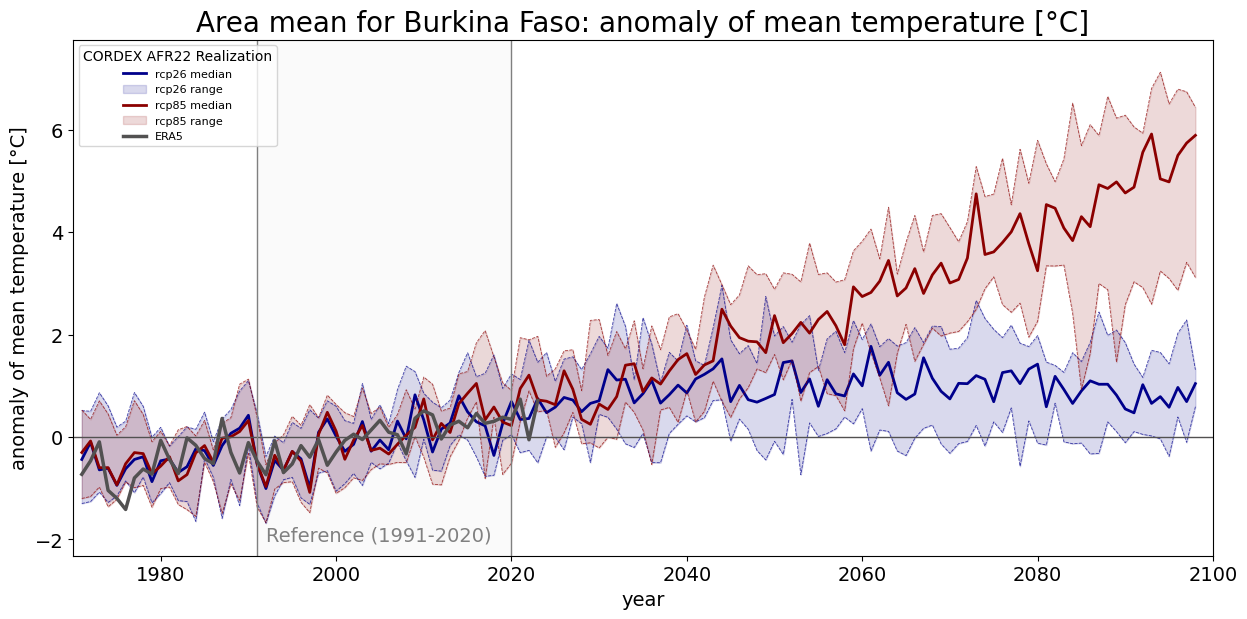

In [97]:
# Chose:
# make line plot with or without ERA5
# anomaly or running_mean_10yr or running_mean_30yr

#line_plot_anomaly(df_anomaly_year, 'year', 'anomaly', outputpath, 'model', country, climate_index, longname)
#line_plot_anomaly(df_anomaly_year, 'year', 'running_mean_10yr', outputpath, 'model', country, climate_index,longname)
#line_plot_anomaly(df_anomaly_year, 'year', 'running_mean_30yr', outputpath, 'model', country, climate_index,longname)
#line_plot_anomaly(df_anomaly_year, 'year', 'anomaly', outputpath, 'scenario_min_max', country, climate_index, longname)
line_plot_anomaly(df_anomaly_year, 'year', 'anomaly', outputpath, 'scenario_min_max', country, climate_index, var_meta['longname'], era5=df_era5_anomalie)

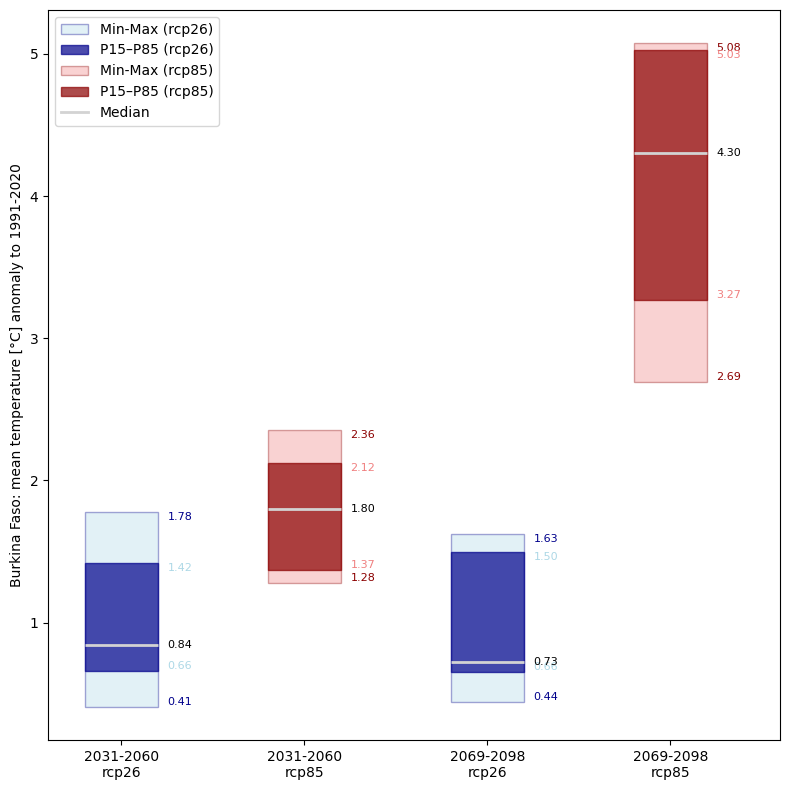

In [87]:
# creat box plot of anomalies for the two time slices
box_plot_anomaly(anom_slice_means, outputpath, country, climate_index, var_meta['longname'])

Saving figure to /work/ch0636/g300047/cicles/factsheet_africa/PLOTS/AFR22_timeseries_v2/TG/TG_Burkina_Faso_timeseries_box_minmax_p15p85.png


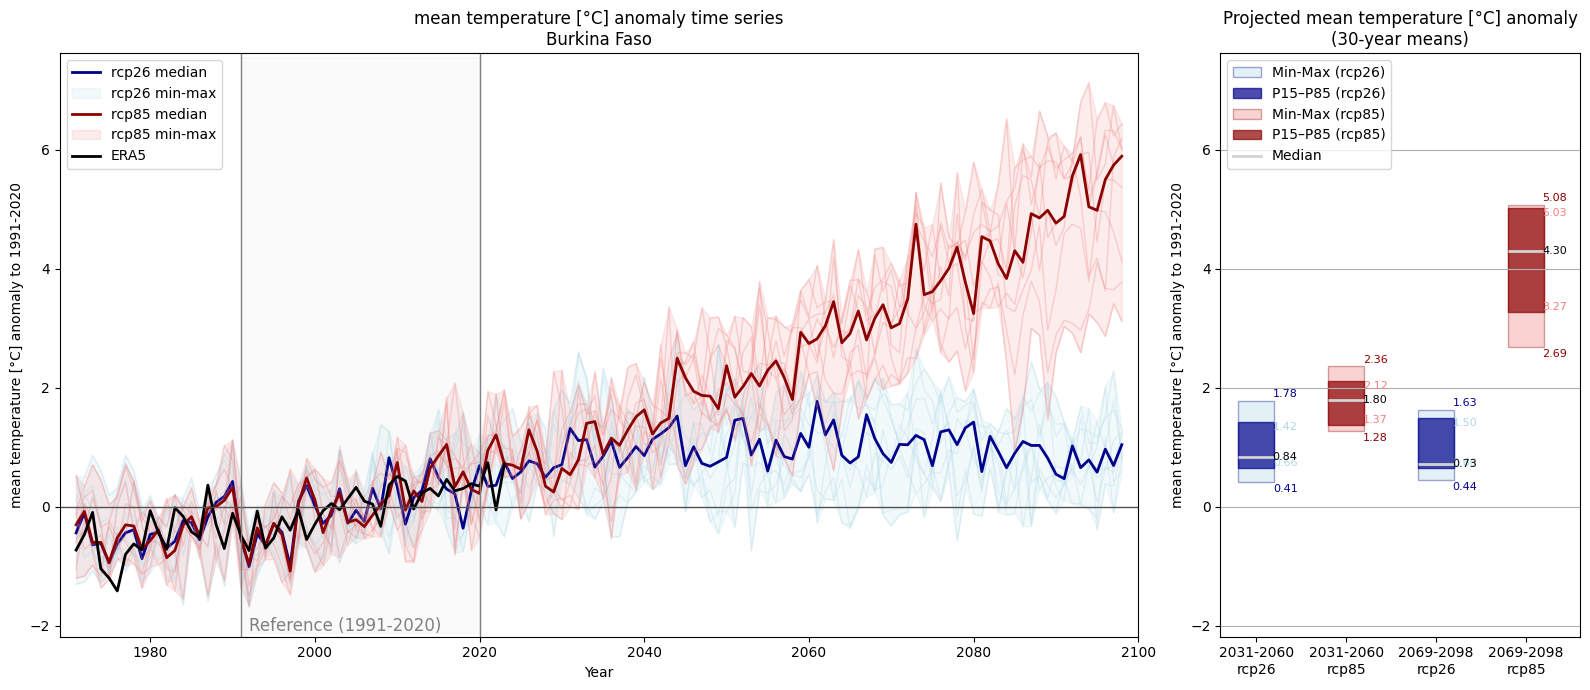

In [101]:
# now line plot with era5 and box plot beside each other in one figure:
lineplot_and_boxplot(df_anomaly_year, df_era5_anomalie, 
                     anom_slice_means, country, climate_index, var_meta['longname'], outputpath)

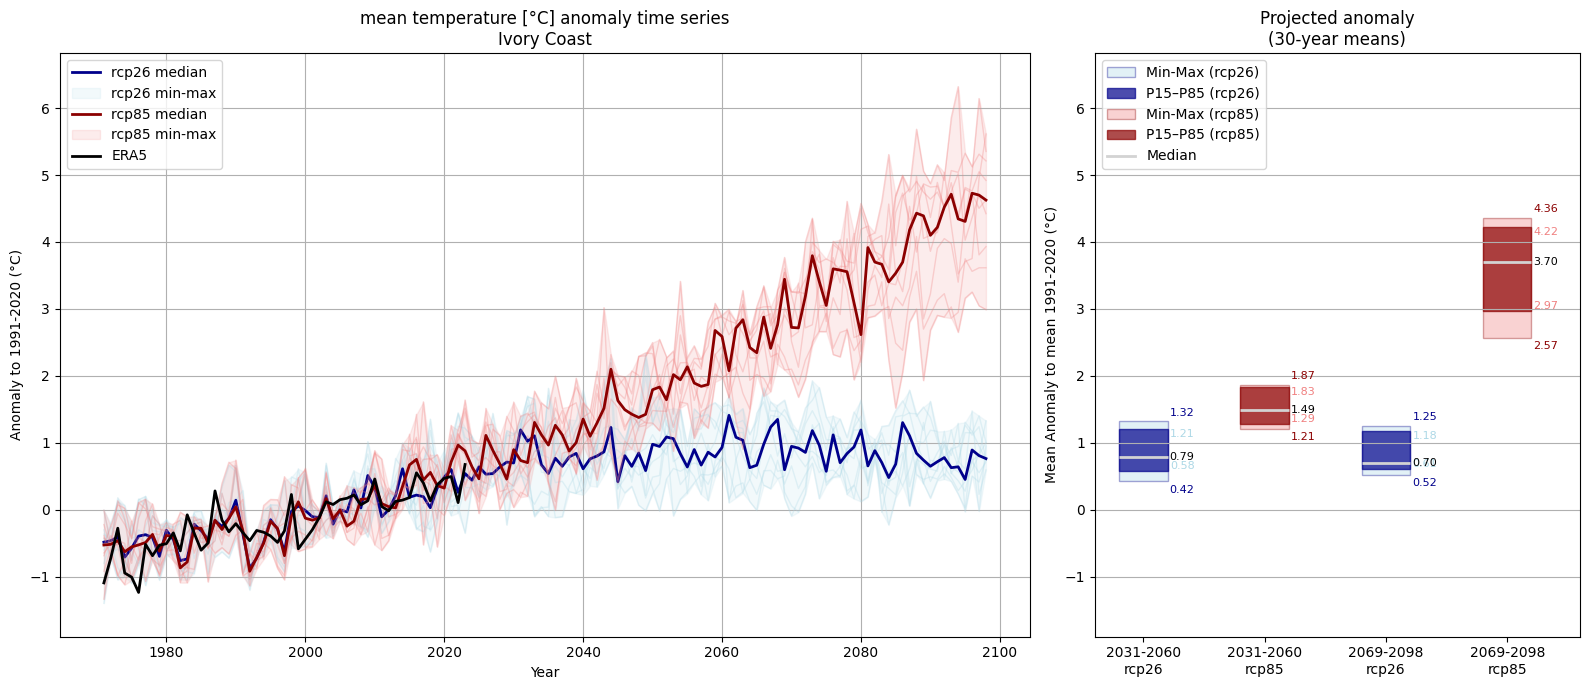

test